# CodeNova Data Science — Tasks 1 & 2

**Task 1: Sales Data Analysis** · **Task 2: Data Cleaning Report**

> **Synthetic data disclosure:** no sales dataset accompanied the assignment brief. The raw records were generated locally with a fixed random seed for demonstration. All totals and recommendations below describe simulated data only.

Run from the repository root. Regenerate `data/sales_raw.csv` with `python src/generate_sales_data.py`, clean it with `python src/clean_data.py`, and create SVG exports with `python src/make_charts.py`.


## 1. Load the cleaned data and confirm its shape

The analysis uses the reproducible cleaned output. The raw file remains intact for Task 2.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
DATA_PATH = ROOT / "data" / "sales_clean.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["order_date"])
print(f"Rows: {len(df):,}; columns: {df.shape[1]}")
print(f"Date range: {df.order_date.min():%Y-%m-%d} to {df.order_date.max():%Y-%m-%d}")
print(f"Missing cells: {df.isna().sum().sum()}; exact duplicates: {df.duplicated().sum()}")
display(df.head())


Rows: 1,773; columns: 12
Date range: 2023-01-02 to 2025-12-31
Missing cells: 0; exact duplicates: 0


,order_id,order_date,region,state,customer_segment,category,subcategory,product_id,units,sales,discount,profit
0,ORD-00001,2023-04-08,Central,IL,Corporate,Furniture,Chairs,SKU-0041,2,124.86,0.382,11.07
1,ORD-00002,2025-04-28,East,FL,Consumer,Technology,Computers,SKU-0224,2,97.87,0.186,22.68
2,ORD-00003,2024-12-18,East,MA,Corporate,Technology,Computers,SKU-0221,7,203.39,0.332,15.52
3,ORD-00004,2024-04-26,Central,TX,Consumer,Furniture,Chairs,SKU-0123,8,413.06,0.244,58.38
4,ORD-00005,2024-04-19,Central,GA,Consumer,Office Supplies,Paper,SKU-0218,2,40.87,0.093,6.83


## 2. Data quality and exploratory profile

These diagnostics check missingness, types, distributions, and anomalies. The separate Task 2 report documents each transformation and rationale.


In [2]:
display(df.describe(include="all").T)
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()}))


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,1773,1770,ORD-00555,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,1773,NaN,NaN,NaN,2024-07-03 11:18:59.086294,2023-01-02 00:00:00,2023-10-01 00:00:00,2024-07-05 00:00:00,2025-04-05 00:00:00,2025-12-31 00:00:00,NaN
region,1773,4,West,585,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,1773,8,FL,246,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_segment,1773,3,Consumer,929,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1773,3,Office Supplies,848,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subcategory,1773,9,Storage,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,1773,250,SKU-0155,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
units,1773.0,NaN,NaN,NaN,4.57586,1.0,3.0,5.0,6.0,64.0,2.686082
sales,1773.0,NaN,NaN,NaN,198.195821,3.15,53.22,108.16,244.47,4963.23,273.618419


,dtype,missing,unique
order_id,str,0,1770
order_date,datetime64[us],0,868
region,str,0,4
state,str,0,8
customer_segment,str,0,3
category,str,0,3
subcategory,str,0,9
product_id,str,0,250
units,int64,0,10
sales,float64,0,1703


## 3. Core business metrics

Profit margin is total profit divided by total sales (weighted margin). AOV is mean line-item sales because this synthetic table models one line per order; in a multi-line order dataset, aggregate to order first.


In [3]:
total_revenue = df["sales"].sum()
total_profit = df["profit"].sum()
weighted_profit_margin = total_profit / total_revenue
average_order_value = df["sales"].mean()  # one synthetic line item per order
units_sold = df["units"].sum()
kpis = pd.DataFrame({"Metric": ["Gross revenue", "Profit", "Weighted profit margin", "Average order value", "Units sold"],
                     "Value": [f"${total_revenue:,.2f}", f"${total_profit:,.2f}", f"{weighted_profit_margin:.1%}", f"${average_order_value:,.2f}", f"{units_sold:,.0f}"]})
display(kpis)


,Metric,Value
0,Gross revenue,"$351,401.19"
1,Profit,"$56,986.38"
2,Weighted profit margin,16.2%
3,Average order value (line-item),$198.20
4,Units sold,"8,113"


## 4. Time trends

Monthly, quarterly, and calendar-month comparisons show trends and seasonal variation in the synthetic series.

In [4]:
monthly = df.set_index("order_date").resample("MS").agg(revenue=("sales", "sum"), profit=("profit", "sum"))
quarterly = df.assign(quarter=df.order_date.dt.to_period("Q")).groupby("quarter").agg(revenue=("sales", "sum"), profit=("profit", "sum"))
seasonality = df.groupby(df.order_date.dt.month)["sales"].mean().reindex(range(1, 13))
print("Highest-revenue quarter:", quarterly.revenue.idxmax(), f"(${quarterly.revenue.max():,.2f})")
print("Highest average-sales calendar month:", int(seasonality.idxmax()), f"(${seasonality.max():,.2f})")
display(monthly.head())


Highest-revenue quarter: 2023Q2 ($47,977.58)
Highest average-sales calendar month: 4 ($263.50)


,revenue,profit
order_date,,
2023-01-01,8830.29,1006.02
2023-02-01,8077.29,1395.98
2023-03-01,5129.30,852.61
2023-04-01,19121.28,3369.97
2023-05-01,15672.01,2642.22


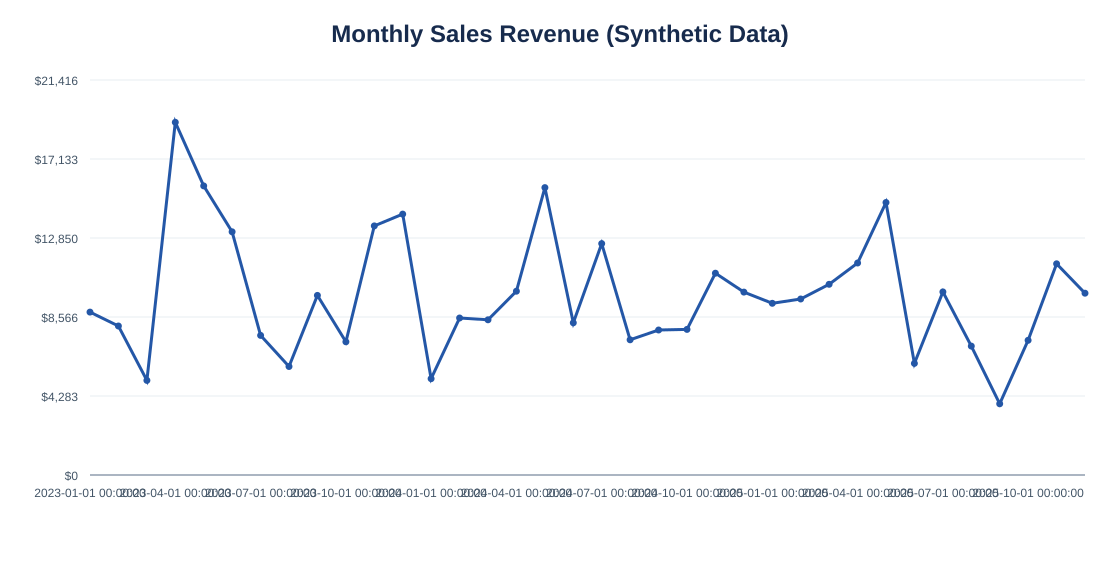

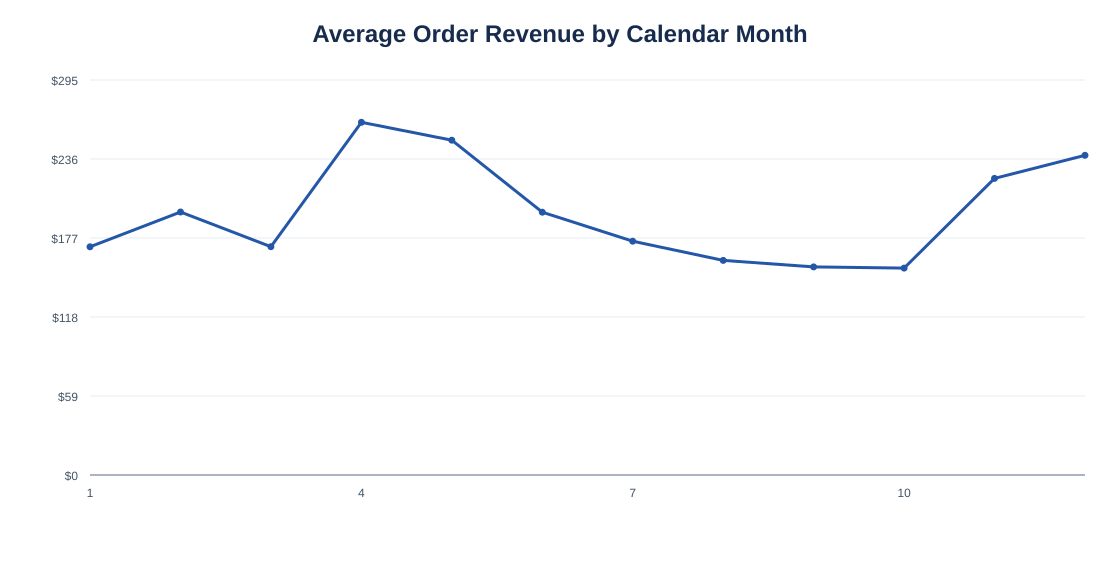

In [5]:
display(SVG(filename=str(ROOT / "figures" / "monthly_revenue.svg")))
display(SVG(filename=str(ROOT / "figures" / "seasonality.svg")))


## 5. Category performance

Compare category revenue, profit, unit volume, and contribution margin. Revenue leaders are not necessarily most profitable per sales dollar.

In [6]:
category = df.groupby("category").agg(revenue=("sales", "sum"), profit=("profit", "sum"), units=("units", "sum"))
category["profit_margin"] = category.profit / category.revenue
category["revenue_share"] = category.revenue / total_revenue
display(category.sort_values("revenue", ascending=False))


,revenue,profit,units,profit_margin,revenue_share
category,,,,,
Technology,179569.90,30571.11,2384,0.170246,0.511011
Furniture,108306.96,12174.58,1982,0.112408,0.308215
Office Supplies,63524.33,14240.69,3747,0.224177,0.180774


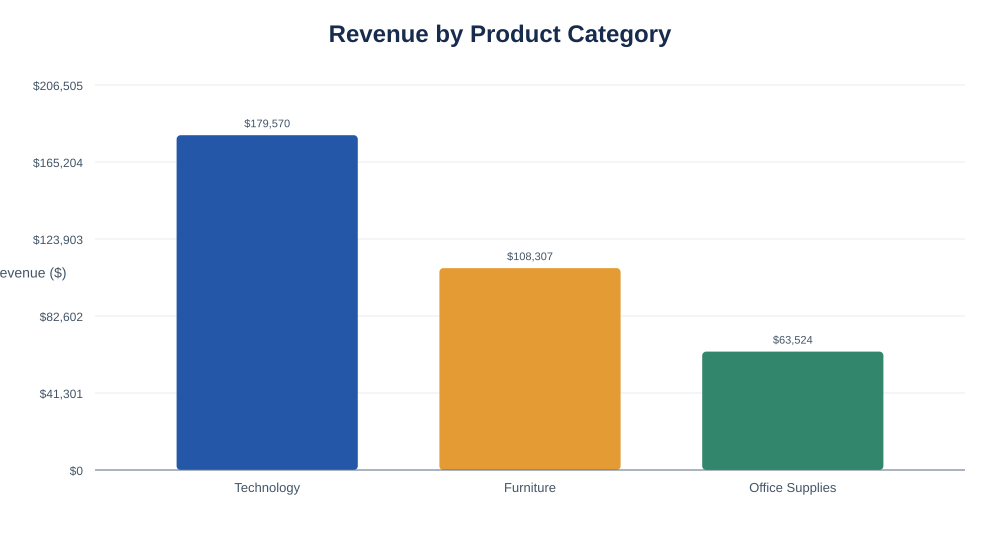

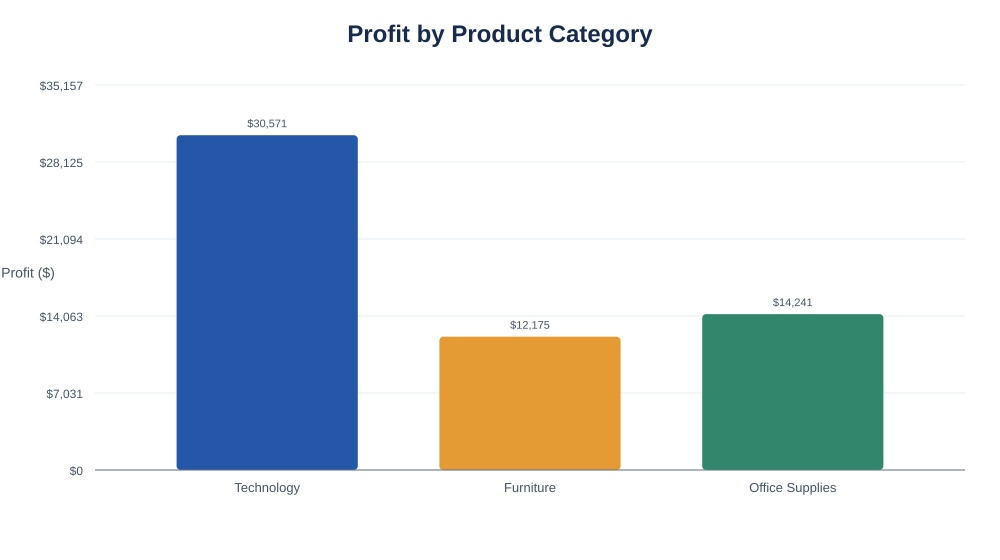

In [7]:
display(SVG(filename=str(ROOT / "figures" / "category_revenue.svg")))
display(SVG(filename=str(ROOT / "figures" / "category_profit.svg")))


## 6. Geographic performance and reconciliation

Only region and state are available for geography; the dataset contains no demographic attributes. Grouped sales must reconcile to the total.

In [8]:
regional_revenue = df.groupby("region")["sales"].sum().sort_values(ascending=False)
reconciliation = pd.DataFrame({"dimension": ["category", "region", "month"],
 "grouped_revenue": [category.revenue.sum(), regional_revenue.sum(), monthly.revenue.sum()],
 "overall_revenue": [total_revenue] * 3})
assert np.allclose(reconciliation.grouped_revenue, reconciliation.overall_revenue)
display(regional_revenue.to_frame("revenue"))
display(reconciliation)


,revenue
region,
West,115081.67
Central,87103.23
East,79058.72
South,70157.57


,dimension,grouped_revenue,overall_revenue
0,category,351401.19,351401.19
1,region,351401.19,351401.19
2,month,351401.19,351401.19


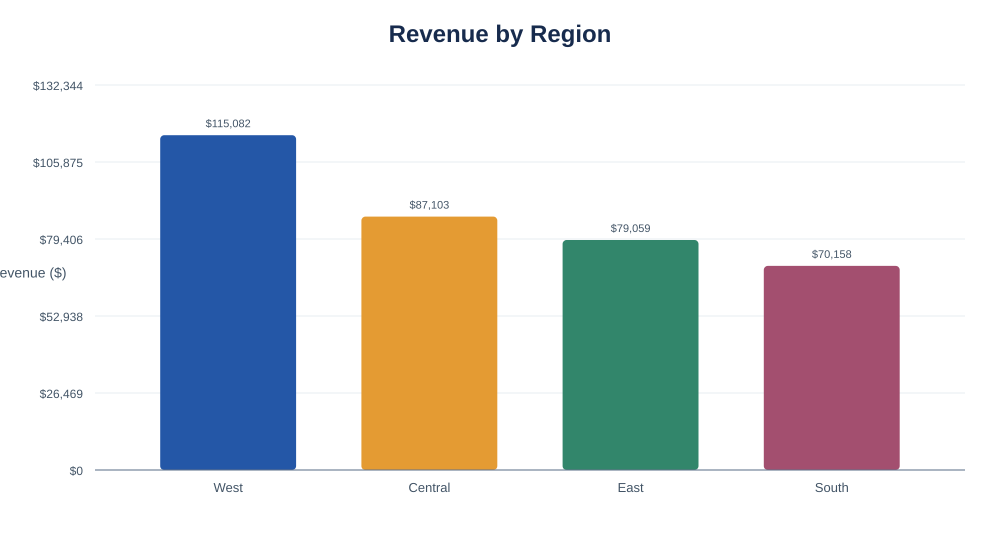

In [9]:
display(SVG(filename=str(ROOT / "figures" / "regional_revenue.svg")))


## 7. Relationships and anomalies

Correlation describes association, not causation. Sales and profit are mechanically related because profit is generated as a fraction of sales in this synthetic example. Large bulk orders are retained and flagged by the Task 2 IQR scan rather than clipped.

In [10]:
numeric_corr = df[["units", "sales", "discount", "profit"]].corr()
display(numeric_corr)


,units,sales,discount,profit
units,1.000000,0.511721,-0.013797,0.496875
sales,0.511721,1.000000,-0.135043,0.781384
discount,-0.013797,-0.135043,1.000000,-0.081884
profit,0.496875,0.781384,-0.081884,1.000000


## 8. Business interpretation and recommendations

- **Scale:** cleaned synthetic records total **$351,401.19 sales**, **$56,986.38 profit**, **16.2% weighted margin**, **$198.20 average line-item value**, and **8,113 units**.
- **Category mix:** Technology contributes **$179,569.90 (51.1%)** of revenue. Office Supplies has the strongest margin (**22.4%**), while Furniture has the weakest (**11.2%**).
- **Geography:** West is largest at **$115,081.67 (32.7%)**. Review regional product mix and discounts before shifting inventory; region alone does not explain why results differ.
- **Seasonality:** the generator deliberately adds seasonal variation. Treat patterns as a demonstration of method and validate them on complete real history before planning.
- **Recommendations:** protect Technology availability; test whether Office Supplies can scale without eroding margin; review discounting and product mix by region; monitor category and regional trends after validating on a governed sales source.

## 9. Data sourcing and limitations

The raw file, cleaning script, and cleaned analysis file are included for reproducibility; see the separate `data-cleaning` repository for the complete quality audit. This is descriptive analysis of simulated records, not causal evidence or a basis for real commercial decisions.
